# Steam Oyunları Veri Seti Üzerinde Veri Ön İşleme (Data Preprocessing)

**Ders:** Makine Öğrenmesi (Yüksek Lisans)
**Konu:** Data Science ve Makine Öğrenmesi için Veri Hazırlama
**Veri seti:** Steam Games Dataset (FronkonGames, Hugging Face: `FronkonGames/steam-games-dataset`, `games.csv`)

---

### Amaç
Bu çalışmada Steam mağazasındaki oyunlara ait gerçek ve "kirli" bir veri seti üzerinde, derste işlenen 10 başlığın tamamı adım adım uygulanmıştır:

| # | Başlık | Bu veri setinde ne yapıldı? |
|---|---|---|
| 1 | Veriyi Tanıma ve Veri Tipleri | Değişkenlerin ölçek türleri (nominal / ordinal / aralık / oran) belirlendi |
| 2 | Veri Kaynağı ve Veri Kalitesi | Bütünlük, geçerlilik, tutarlılık, güncellik kontrolleri yapıldı; **kayık başlık hatası** bulundu |
| 3 | Veri Temizleme | Metin-liste kolonları ayrıştırıldı, tarih/aralık kolonları dönüştürüldü |
| 4 | Eksik Veri Analizi | Gizli eksikler (`""`, `[]`, yapısal 0) ortaya çıkarıldı, MCAR/MAR/MNAR tartışıldı |
| 5 | Aykırı Değerler | IQR ve z-skor ile tespit; hata mı gerçek mi ayrımı yapıldı |
| 6 | Tekrarlı / Tutarsız / Gürültülü Veri | Tekrarlar, mantıksal çelişkiler, birim (dakika→saat) dönüşümü |
| 7 | Dönüşüm, Ölçekleme, Normalizasyon | log1p, Yeo-Johnson, Standard/MinMax/Robust karşılaştırması |
| 8 | Keşifsel Veri Analizi (EDA) | Dağılımlar, ilişkiler, dengesizlik görselleştirildi |
| 9 | Özellik Mühendisliği ve Seçimi | ~40 yeni özellik üretildi, varyans/korelasyon/MI ile seçim yapıldı |
| 10 | ML'e Hazır Veri ve Data Leakage | Sızıntılı ve temiz model karşılaştırıldı, Pipeline kuruldu |

> **Çalıştırma notu:** Veri seti, Kaggle'daki arşiv bozuk olduğu için Hugging Face'ten (`FronkonGames/steam-games-dataset`) `hf_hub_download` ile otomatik indirilir. İndirme başarısız olursa klasördeki `games.csv`, o da yoksa örnek dosya (`games_sample.csv`) kullanılır.

In [1]:
%pip install -q huggingface_hub

In [2]:
import ast
import csv
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler,
                                   PowerTransformer, MultiLabelBinarizer)
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, f1_score, classification_report

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)
RANDOM_STATE = 42

# Veriyi Hugging Face'ten indir (Kaggle'daki arşiv bozuk)
try:
    from huggingface_hub import hf_hub_download
    DATA_PATH = hf_hub_download(repo_id="FronkonGames/steam-games-dataset",
                                filename="games.csv", repo_type="dataset")
except Exception as e:
    print("Hugging Face'ten indirilemedi:", e)
    DATA_PATH = "games.csv" if os.path.exists("games.csv") else "games_sample.csv"
print("Kullanılan dosya:", DATA_PATH)

games.csv: reconstructing file:   0%|          |  0.00B /  401MB            

games.csv: downloading bytes:           |  0.00B            

Kullanılan dosya: /root/.cache/huggingface/hub/datasets--FronkonGames--steam-games-dataset/snapshots/0fc4ab0ea56f668a0c69f6a96c4727177343e198/games.csv


---
## 1. Veriyi Tanıma ve Veri Tipleri (Data Types)

### 1.1 Veriyi okurken karşılaşılan ilk kalite problemi: Kayık başlık satırı
Dosya ilk açıldığında başlık satırında **39**, veri satırlarında ise **40** alan olduğu görülür. Sebep, başlıkta `Discount` ve `DLC count` kolonlarının arada virgül olmadan **`DiscountDLC count`** şeklinde birleşmiş olmasıdır.

Bu hata (dosyanın sürümüne göre) fark edilmezse `pd.read_csv` fazladan ilk kolonu indeks yapar ve **tüm kolonlar bir sağa kayar** (ör. `Price` kolonunda aslında `Required age` değerleri görünür). Bu, en tehlikeli hata türüdür çünkü kod hata vermez, sadece yanlış sonuç üretir. Önce problemi kanıtlayıp sonra düzeltiyoruz.

In [3]:
with open(DATA_PATH, encoding="utf-8") as f:
    reader = csv.reader(f)
    header = next(reader)
    first_row = next(reader)

print("Başlıktaki kolon sayısı :", len(header))
print("İlk satırdaki alan sayısı:", len(first_row))
print("Şüpheli başlık          :", [h for h in header if "Discount" in h])

# Hatalı (naif) okuma ne üretir?
naive = pd.read_csv(DATA_PATH, nrows=3)
if len(first_row) == len(header) + 1:
    print("\nNaif okumada 'Name' kolonunda görünenler:", naive["Name"].tolist())
    print("Naif okumada 'Price' kolonunda görünenler:", naive["Price"].tolist(), " <-- aslında Required age!")
else:
    print("\nBu sürümde başlık ve satır alan sayıları eşit; kayma yok.")

Başlıktaki kolon sayısı : 39
İlk satırdaki alan sayısı: 40
Şüpheli başlık          : ['DiscountDLC count']

Naif okumada 'Name' kolonunda görünenler: ['Aug 1, 2023', 'Jul 29, 2016', 'May 6, 2019']
Naif okumada 'Price' kolonunda görünenler: [0, 65, 0]  <-- aslında Required age!


In [4]:
def load_steam(path):
    """Kayık başlığı düzelterek Steam veri setini okur."""
    with open(path, encoding="utf-8") as f:
        reader = csv.reader(f)
        hdr = next(reader)
        row = next(reader)
    names = hdr
    if len(row) == len(hdr) + 1 and "DiscountDLC count" in hdr:
        i = hdr.index("DiscountDLC count")
        names = hdr[:i] + ["Discount", "DLC count"] + hdr[i + 1:]
        print("Başlık düzeltildi: 'DiscountDLC count' -> 'Discount', 'DLC count'")
    return pd.read_csv(path, names=names, header=0, low_memory=False)

raw = load_steam(DATA_PATH)
df = raw.copy()
print("Boyut (satır, kolon):", df.shape)
df.head(3)

Başlık düzeltildi: 'DiscountDLC count' -> 'Discount', 'DLC count'
Boyut (satır, kolon): (125855, 40)


,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,Supported languages,Full audio languages,Reviews,Header image,Website,Support url,Support email,Windows,Mac,Linux,Metacritic score,Metacritic url,User score,Positive,Negative,Score rank,Achievements,Recommendations,Notes,Average playtime forever,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0,0.00,0,0,NaN,[],[],NaN,https://shared.akamai.steamstatic.com/store_it...,NaN,NaN,NaN,True,False,False,0,NaN,0,0,0,NaN,0,0,NaN,0,0,0,0,NaN,NaN,NaN,NaN,NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.24,65,0,"Springtime, April: when the cherry trees come ...",['English'],[],NaN,https://shared.akamai.steamstatic.com/store_it...,http://mangagamer.org/supipara,http://mangagamer.com,support@mangagamer.com,True,False,False,0,NaN,0,252,3,NaN,0,231,NaN,8,0,8,0,minori,MangaGamer,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",https://shared.akamai.steamstatic.com/store_it...,NaN
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.99,0,0,"Immerse yourself in the most beloved, mystical...","['English', 'French', 'German', 'Russian']",[],NaN,https://shared.akamai.steamstatic.com/store_it...,https://www.facebook.com/8FloorGames/,https://www.facebook.com/8FloorGames,support@8floor.net,True,True,False,0,NaN,0,21,3,NaN,0,0,NaN,0,0,0,0,Somer Games,8floor,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",https://shared.akamai.steamstatic.com/store_it...,NaN


### 1.2 Pandas veri tipleri
Pandas'ın atadığı teknik tipler (`int64`, `float64`, `bool`, `object`) değişkenin **anlamını** her zaman doğru yansıtmaz. Örneğin `Release date` ve `Estimated owners` metin olarak okunmuştur; `Supported languages` ise aslında bir Python listesinin metne dökülmüş hâlidir.

In [5]:
df.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125855 entries, 0 to 125854
Data columns (total 40 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   AppID                       125855 non-null  int64  
 1   Name                        125854 non-null  object 
 2   Release date                125855 non-null  object 
 3   Estimated owners            125855 non-null  object 
 4   Peak CCU                    125855 non-null  int64  
 5   Required age                125855 non-null  int64  
 6   Price                       125855 non-null  float64
 7   Discount                    125855 non-null  int64  
 8   DLC count                   125855 non-null  int64  
 9   About the game              117393 non-null  object 
 10  Supported languages         125855 non-null  object 
 11  Full audio languages        125855 non-null  object 
 12  Reviews                     12181 non-null   object 
 13  Header image  

### 1.3 Ölçek türlerine göre sınıflandırma
Hangi istatistiğin ve hangi dönüşümün uygulanabileceği değişkenin **ölçme düzeyine** bağlıdır:

- **Nominal:** Sadece kategori, sıralama yok (mod, frekans) → One-hot / multi-hot
- **Ordinal:** Sıralı kategori (medyan, yüzdelik) → Sıralı kodlama
- **Aralık (Interval):** Eşit aralık, gerçek sıfır yok (tarih)
- **Oran (Ratio):** Gerçek sıfır var, oran anlamlı (fiyat, süre, sayım) → Ortalama, log, ölçekleme
- **Kimlik / Metin / URL:** Doğrudan modele girmez; ya atılır ya da özellik türetilir

In [6]:
variable_types = {
    "AppID": ("Kimlik", "Nominal (ID)", "Modele girmez, tekrar kontrolünde kullanılır"),
    "Name": ("Metin", "Nominal", "Gürültü/tekrar kontrolü"),
    "Release date": ("Tarih", "Aralık", "Yıl, ay, yaş özellikleri türetilecek"),
    "Estimated owners": ("Kategorik aralık", "Ordinal", "Alt/üst sınır ve orta nokta çıkarılacak"),
    "Peak CCU": ("Sayısal (sayım)", "Oran", "Çok çarpık -> log"),
    "Required age": ("Sayısal", "Ordinal", "Yaş sınırı kategorisi"),
    "Price": ("Sayısal (sürekli)", "Oran", "Çarpık -> log"),
    "Discount": ("Sayısal", "Oran (%)", "0-100 arası olmalı"),
    "DLC count": ("Sayısal (sayım)", "Oran", ""),
    "About the game": ("Serbest metin", "-", "Uzunluk özelliği türetilecek"),
    "Supported languages": ("Liste-metin", "Nominal (çok etiketli)", "Dil sayısı türetilecek"),
    "Full audio languages": ("Liste-metin", "Nominal (çok etiketli)", "Dil sayısı türetilecek"),
    "Reviews": ("Serbest metin", "-", "Çoğunlukla boş"),
    "Header image": ("URL", "-", "Atılacak"),
    "Website": ("URL", "-", "Var/yok bayrağı"),
    "Support url": ("URL", "-", "Var/yok bayrağı"),
    "Support email": ("Metin", "-", "Var/yok bayrağı"),
    "Windows": ("Mantıksal", "Nominal (ikili)", ""),
    "Mac": ("Mantıksal", "Nominal (ikili)", ""),
    "Linux": ("Mantıksal", "Nominal (ikili)", ""),
    "Metacritic score": ("Sayısal", "Aralık/Oran (0-100)", "0 = eksik (yapısal)"),
    "Metacritic url": ("URL", "-", "Atılacak"),
    "User score": ("Sayısal", "Aralık", "0 = eksik (yapısal)"),
    "Positive": ("Sayısal (sayım)", "Oran", "Hedef türetmede kullanılacak (sızıntı riski)"),
    "Negative": ("Sayısal (sayım)", "Oran", "Hedef türetmede kullanılacak (sızıntı riski)"),
    "Score rank": ("Sayısal", "Ordinal", "Neredeyse tamamen boş"),
    "Achievements": ("Sayısal (sayım)", "Oran", ""),
    "Recommendations": ("Sayısal (sayım)", "Oran", "Sızıntı riski"),
    "Notes": ("Serbest metin", "-", "İçerik uyarısı bayrağı"),
    "Average playtime forever": ("Sayısal (dakika)", "Oran", "Saate çevrilecek"),
    "Average playtime two weeks": ("Sayısal (dakika)", "Oran", "Saate çevrilecek"),
    "Median playtime forever": ("Sayısal (dakika)", "Oran", "Saate çevrilecek"),
    "Median playtime two weeks": ("Sayısal (dakika)", "Oran", "Saate çevrilecek"),
    "Developers": ("Liste-metin", "Nominal (yüksek kardinalite)", "Normalize edilecek"),
    "Publishers": ("Liste-metin", "Nominal (yüksek kardinalite)", "Normalize edilecek"),
    "Categories": ("Liste-metin", "Nominal (çok etiketli)", "Bayraklara çevrilecek"),
    "Genres": ("Liste-metin", "Nominal (çok etiketli)", "Multi-hot kodlanacak"),
    "Tags": ("Liste-metin", "Nominal (çok etiketli)", "Etiket sayısı"),
    "Screenshots": ("URL listesi", "-", "Sayıya çevrilip atılacak"),
    "Movies": ("URL listesi", "-", "Sayıya çevrilip atılacak"),
}
vt = (pd.DataFrame.from_dict(variable_types, orient="index",
                             columns=["Mantıksal tip", "Ölçek", "Planlanan işlem"])
        .rename_axis("Kolon"))
vt.insert(0, "Pandas tipi", df.dtypes.astype(str).reindex(vt.index))
vt

,Pandas tipi,Mantıksal tip,Ölçek,Planlanan işlem
Kolon,,,,
AppID,int64,Kimlik,Nominal (ID),"Modele girmez, tekrar kontrolünde kullanılır"
Name,object,Metin,Nominal,Gürültü/tekrar kontrolü
Release date,object,Tarih,Aralık,"Yıl, ay, yaş özellikleri türetilecek"
Estimated owners,object,Kategorik aralık,Ordinal,Alt/üst sınır ve orta nokta çıkarılacak
Peak CCU,int64,Sayısal (sayım),Oran,Çok çarpık -> log
Required age,int64,Sayısal,Ordinal,Yaş sınırı kategorisi
Price,float64,Sayısal (sürekli),Oran,Çarpık -> log
Discount,int64,Sayısal,Oran (%),0-100 arası olmalı
DLC count,int64,Sayısal (sayım),Oran,


In [7]:
print("Ölçek türlerine göre kolon sayısı:")
vt["Ölçek"].str.split(" ").str[0].value_counts()

Ölçek türlerine göre kolon sayısı:


,count
Ölçek,
Nominal,12
Oran,12
-,10
Ordinal,3
Aralık,2
Aralık/Oran,1


---
## 2. Veri Toplama, Kaynaklar ve Veri Kalitesi

### 2.1 Verinin kaynağı
- **Kaynak:** Kaggle'da yayınlanan *Steam Games Dataset* (FronkonGames). Veriler **Steam Store API**'den ve oyun sahibi/oynama süresi tahminleri için **SteamSpy API**'den kazınarak (scraping) toplanmıştır.
- **Toplama yöntemi:** Gözlemsel, otomatik web kazıma. Deneysel değil.
- **Bu yöntemin getirdiği riskler:**
  - `Estimated owners`, `Peak CCU`, oynama süreleri **ölçüm değil tahmindir** (SteamSpy örneklemesi).
  - Kazıma sırasında alanlar boş kalabilir ya da `""`, `[]`, `0` gibi "eksik ama eksik görünmeyen" değerlerle doldurulabilir.
  - Veri bir anlık görüntüdür (snapshot); yorum sayıları zamanla değişir.
  - Başlıktaki kolon kayması (Bölüm 1) üretim sürecindeki bir yazılım hatasıdır.

### 2.2 Kalite boyutları
Veri kalitesini dört boyutta ölçüyoruz: **Bütünlük (completeness), Geçerlilik (validity), Tutarlılık (consistency), Teklik (uniqueness)**.

In [8]:
# Bütünlük: NaN + boş string + boş liste "[]" gerçek eksiklik sayılır
def is_effectively_missing(s):
    m = s.isna()
    if s.dtype == object:
        st = s.astype(str).str.strip()
        m = m | st.isin(["", "[]", "nan"])
    return m

completeness = pd.DataFrame({
    "NaN oranı (%)": df.isna().mean() * 100,
    "Gerçek eksik oranı (%)": pd.DataFrame({c: is_effectively_missing(df[c]) for c in df.columns}).mean() * 100,
}).round(2).sort_values("Gerçek eksik oranı (%)", ascending=False)
completeness.head(20)

,NaN oranı (%),Gerçek eksik oranı (%)
Movies,100.00,100.00
Score rank,99.97,99.97
Metacritic url,96.62,96.62
Reviews,90.32,90.32
Notes,81.48,81.48
Website,59.86,59.86
Full audio languages,0.00,59.29
Support url,56.06,56.06
Tags,33.77,33.77
Support email,17.98,17.98


`NaN oranı` ile `Gerçek eksik oranı` arasındaki fark, pandas'ın **görmediği** eksiklerdir (`"[]"` gibi). Bunlar ayrıca ele alınmazsa eksik veri analizi yanıltıcı olur.

In [9]:
# Geçerlilik (validity) kuralları: her kural ihlal edilen satır sayısını döndürür
release_parsed = pd.to_datetime(df["Release date"], format="mixed", errors="coerce")
snapshot_date = pd.Timestamp("2026-10-12")

validity_rules = {
    "Price < 0": (df["Price"] < 0).sum(),
    "Discount 0-100 dışında": (~df["Discount"].between(0, 100)).sum(),
    "Metacritic score 0-100 dışında": (~df["Metacritic score"].between(0, 100)).sum(),
    "Negatif sayımlar (Positive/Negative/DLC)": ((df[["Positive", "Negative", "DLC count"]] < 0).any(axis=1)).sum(),
    "Required age 0-21 dışında": (~df["Required age"].between(0, 21)).sum(),
    "Release date ayrıştırılamıyor": (release_parsed.isna() & df["Release date"].notna()).sum(),
    "Release date gelecekte": (release_parsed > snapshot_date).sum(),
    "Estimated owners formatı bozuk": (~df["Estimated owners"].astype(str).str.match(r"^\d+ - \d+$")).sum(),
}
pd.Series(validity_rules, name="İhlal sayısı").to_frame()

,İhlal sayısı
Price < 0,0
Discount 0-100 dışında,0
Metacritic score 0-100 dışında,0
Negatif sayımlar (Positive/Negative/DLC),0
Required age 0-21 dışında,0
Release date ayrıştırılamıyor,0
Release date gelecekte,1
Estimated owners formatı bozuk,0


In [10]:
# Tutarlılık (consistency) ve teklik (uniqueness)
consistency_rules = {
    "Son 2 hafta süresi > toplam süre": (df["Average playtime two weeks"] > df["Average playtime forever"]).sum(),
    "Ücretsiz oyunda indirim > 0": ((df["Price"] == 0) & (df["Discount"] > 0)).sum(),
    "Sahip '0 - 0' ama yorum var": ((df["Estimated owners"] == "0 - 0") & ((df["Positive"] + df["Negative"]) > 0)).sum(),
    "Hiçbir platform desteklenmiyor": (~(df["Windows"] | df["Mac"] | df["Linux"])).sum(),
    "Tekrarlı AppID": df["AppID"].duplicated().sum(),
    "Tamamen tekrarlı satır": df.duplicated().sum(),
}
pd.Series(consistency_rules, name="Satır sayısı").to_frame()

,Satır sayısı
Son 2 hafta süresi > toplam süre,367
Ücretsiz oyunda indirim > 0,39
Sahip '0 - 0' ama yorum var,0
Hiçbir platform desteklenmiyor,0
Tekrarlı AppID,0
Tamamen tekrarlı satır,0


In [11]:
quality_summary = pd.Series({
    "Ortalama bütünlük (%)": 100 - completeness["Gerçek eksik oranı (%)"].mean(),
    "Geçerlilik ihlali olan kural sayısı": sum(v > 0 for v in validity_rules.values()),
    "Tutarlılık ihlali olan kural sayısı": sum(v > 0 for v in consistency_rules.values()),
    "Satır sayısı": len(df),
}).round(2)
quality_summary

,0
Ortalama bütünlük (%),81.47
Geçerlilik ihlali olan kural sayısı,1.00
Tutarlılık ihlali olan kural sayısı,2.00
Satır sayısı,125855.00


**Yorum:** Veri seti tam bir "kirli gerçek dünya verisi"dir: başlık hatası, gizli eksikler, tahmini (ölçülmemiş) değişkenler ve mantıksal çelişkiler içermektedir. Bu nedenle analize güvenmeden önce sonraki bölümlerdeki temizlik adımları zorunludur.

---
## 3. Veri Temizleme ve Ön İşleme (Data Cleaning & Preprocessing)

Ham metin yapısındaki kolonları analiz edilebilir, tutarlı ve izlenebilir bir yapıya dönüştürüyoruz. Her adım ayrı fonksiyon olarak yazıldı; böylece süreç **tekrarlanabilir** ve yeni veriye aynen uygulanabilir.

In [12]:
def parse_py_list(x):
    """"['English', 'French']" -> ['English', 'French']"""
    if pd.isna(x):
        return []
    try:
        v = ast.literal_eval(x)
        return [str(i).strip() for i in v] if isinstance(v, (list, tuple)) else []
    except (ValueError, SyntaxError):
        return []

def parse_comma_list(x):
    """"Action,Indie" -> ['Action', 'Indie']"""
    if pd.isna(x) or str(x).strip() == "":
        return []
    return [i.strip() for i in str(x).split(",") if i.strip()]

def normalize_text(x):
    """Baştaki/sondaki boşluklar ve çoklu boşluklar temizlenir."""
    if pd.isna(x):
        return np.nan
    x = re.sub(r"\s+", " ", str(x)).strip()
    return x if x else np.nan

clean = df.copy()

# 3.1 Metin kolonlarını normalize et ve gizli eksikleri NaN yap
text_cols = clean.select_dtypes(include="object").columns
for c in text_cols:
    clean[c] = clean[c].map(normalize_text)
clean = clean.replace({"[]": np.nan})

# 3.2 Tarih
clean["release_date"] = pd.to_datetime(clean["Release date"], format="mixed", errors="coerce")

# 3.3 Estimated owners: "0 - 20000" -> alt sınır, üst sınır, orta nokta
owners = clean["Estimated owners"].str.extract(r"(\d+)\s*-\s*(\d+)").astype(float)
clean["owners_low"], clean["owners_high"] = owners[0], owners[1]
clean["owners_mid"] = (owners[0] + owners[1]) / 2

# 3.4 Liste-metin kolonlarını gerçek listelere dönüştür
clean["languages_list"] = clean["Supported languages"].map(parse_py_list)
clean["audio_languages_list"] = clean["Full audio languages"].map(parse_py_list)
for c in ["Categories", "Genres", "Tags", "Developers", "Publishers", "Screenshots", "Movies"]:
    clean[c + "_list"] = clean[c].map(parse_comma_list)

clean[["Release date", "release_date", "Estimated owners", "owners_low", "owners_high",
       "Supported languages", "languages_list", "Genres_list"]].head()

,Release date,release_date,Estimated owners,owners_low,owners_high,Supported languages,languages_list,Genres_list
0,"Aug 1, 2023",2023-08-01,0 - 0,0.0,0.0,NaN,[],[]
1,"Jul 29, 2016",2016-07-29,0 - 20000,0.0,20000.0,['English'],[English],[Adventure]
2,"May 6, 2019",2019-05-06,0 - 20000,0.0,20000.0,"['English', 'French', 'German', 'Russian']","[English, French, German, Russian]",[Casual]
3,"Oct 31, 2024",2024-10-31,0 - 20000,0.0,20000.0,['Korean'],[Korean],"[Casual, Indie, Simulation]"
4,"Apr 24, 2025",2025-04-24,0 - 20000,0.0,20000.0,['English'],[English],"[Action, Early Access]"


In [13]:
# 3.5 Bilgi taşımayan URL kolonlarından önce özellik türetilir, sonra atılır
clean["n_screenshots"] = clean["Screenshots_list"].str.len()
clean["n_movies"] = clean["Movies_list"].str.len()
clean["has_website"] = clean["Website"].notna().astype(int)
clean["has_support_contact"] = (clean["Support url"].notna() | clean["Support email"].notna()).astype(int)
clean["has_content_notes"] = clean["Notes"].notna().astype(int)

drop_cols = ["Header image", "Website", "Support url", "Support email", "Metacritic url",
             "Screenshots", "Movies", "Screenshots_list", "Movies_list", "Reviews", "Release date"]
clean = clean.drop(columns=drop_cols)

# 3.6 Kolon isimlerini standartlaştır (snake_case)
clean.columns = [re.sub(r"[^0-9a-zA-Z]+", "_", c).strip("_").lower() for c in clean.columns]
print("Temizlik sonrası boyut:", clean.shape)
print(list(clean.columns))

Temizlik sonrası boyut: (125855, 47)
['appid', 'name', 'estimated_owners', 'peak_ccu', 'required_age', 'price', 'discount', 'dlc_count', 'about_the_game', 'supported_languages', 'full_audio_languages', 'windows', 'mac', 'linux', 'metacritic_score', 'user_score', 'positive', 'negative', 'score_rank', 'achievements', 'recommendations', 'notes', 'average_playtime_forever', 'average_playtime_two_weeks', 'median_playtime_forever', 'median_playtime_two_weeks', 'developers', 'publishers', 'categories', 'genres', 'tags', 'release_date', 'owners_low', 'owners_high', 'owners_mid', 'languages_list', 'audio_languages_list', 'categories_list', 'genres_list', 'tags_list', 'developers_list', 'publishers_list', 'n_screenshots', 'n_movies', 'has_website', 'has_support_contact', 'has_content_notes']


**Uygulanan temizlik adımları özeti:**
1. Metinlerde boşluk normalizasyonu ve `""` / `"[]"` → `NaN` dönüşümü
2. `Release date` → `datetime`
3. `Estimated owners` → sayısal alt/üst sınır ve orta nokta (ordinal → sayısal)
4. Python-liste ve virgüllü metinler → gerçek listeler
5. URL kolonlarından *var/yok* ve *adet* özellikleri türetilip kolonlar atıldı (`Reviews` kolonu neredeyse tamamen boş olduğu için atıldı)
6. Kolon adları `snake_case` yapıldı

---
## 4. Eksik Veri Analizi ve Yönetimi (Missing Data)

Eksiklik yalnızca doldurulacak bir boşluk değildir; **veri üretim sürecinin bir sinyalidir**. Bu veri setinde üç tür eksik vardır:
1. **Açık eksik:** `NaN`
2. **Gizli eksik:** `""`, `"[]"` (Bölüm 3'te NaN'a çevrildi)
3. **Yapısal eksik:** `metacritic_score = 0`, `user_score = 0` gibi; puan *sıfır* değil, *hiç verilmemiş* demektir.

In [14]:
# Yapısal sıfırları NaN'a çevir
for c in ["metacritic_score", "user_score", "score_rank"]:
    clean[c] = clean[c].replace(0, np.nan)

missing = (clean.drop(columns=[c for c in clean.columns if c.endswith("_list")])
                .isna().mean().mul(100).round(2)
                .sort_values(ascending=False))
missing = missing[missing > 0]
missing.to_frame("Eksik (%)")

,Eksik (%)
score_rank,99.97
user_score,99.97
metacritic_score,96.62
notes,81.48
full_audio_languages,59.29
tags,33.77
categories,7.12
publishers,7.09
about_the_game,6.72
developers,6.71


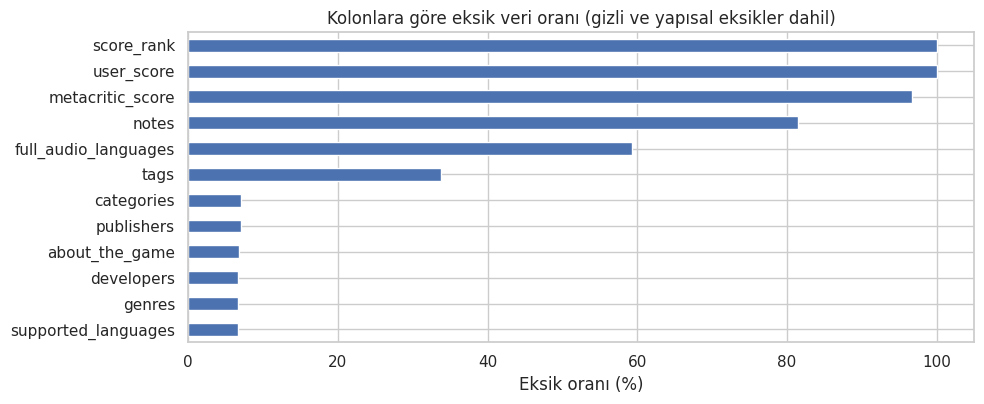

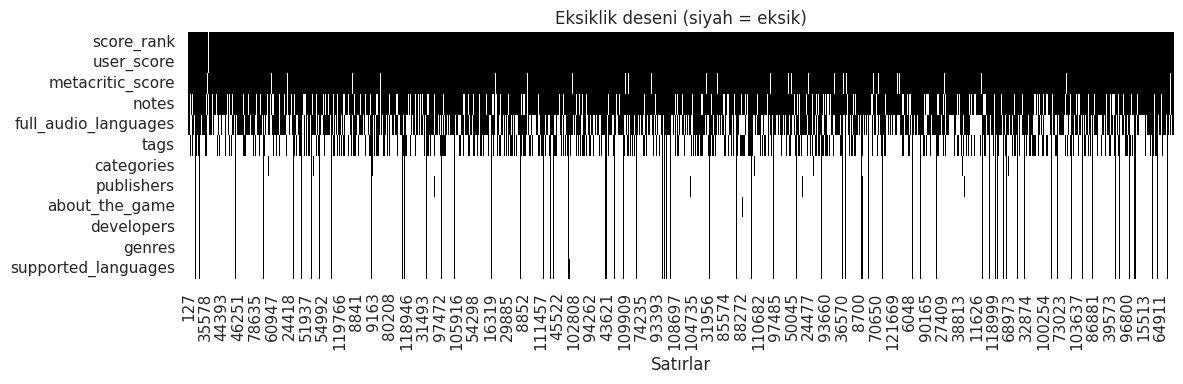

In [15]:
if len(missing):
    fig, ax = plt.subplots(figsize=(10, max(3, 0.35 * len(missing))))
    missing.sort_values().plot.barh(ax=ax, color="#4C72B0")
    ax.set_xlabel("Eksik oranı (%)")
    ax.set_title("Kolonlara göre eksik veri oranı (gizli ve yapısal eksikler dahil)")
    plt.tight_layout(); plt.show()

    # Eksiklik deseni (rastgele 1000 satır)
    sample_rows = clean[missing.index].sample(min(1000, len(clean)), random_state=RANDOM_STATE)
    plt.figure(figsize=(12, 4))
    sns.heatmap(sample_rows.isna().T, cbar=False, cmap="Greys")
    plt.title("Eksiklik deseni (siyah = eksik)"); plt.xlabel("Satırlar"); plt.tight_layout(); plt.show()

### 4.1 Eksiklik mekanizması: MCAR mı, MAR mı, MNAR mı?
Metacritic puanının eksik olup olmaması rastgele mi? Eğer eksiklik **gözlenen başka bir değişkenle** (ör. popülerlik) ilişkiliyse mekanizma **MAR** (ya da MNAR) olur; bu durumda eksik satırları silmek örneklemi sistematik olarak bozar.

In [16]:
clean["total_reviews"] = clean["positive"] + clean["negative"]
mc_missing = clean["metacritic_score"].isna().map({True: "Metacritic YOK", False: "Metacritic VAR"})
comparison = clean.groupby(mc_missing)[["total_reviews", "price", "owners_mid", "peak_ccu"]].median()
comparison

,total_reviews,price,owners_mid,peak_ccu
metacritic_score,,,,
Metacritic VAR,1482.5,4.49,150000.0,4.0
Metacritic YOK,5.0,2.09,10000.0,0.0


**Yorum:** Metacritic puanı olan oyunlar medyan olarak çok daha fazla yorum ve sahibe sahiptir. Yani eksiklik **rastgele değildir (MCAR değil)**; küçük/bağımsız oyunlar eleştirmenlerce puanlanmamaktadır (MAR). Bu nedenle:
- Metacritic eksik satırları **silinmez** (silinirse veri büyük oyunlara doğru yanlı olur).
- Eksikliğin kendisi bilgi taşıdığı için **eksiklik göstergesi** (`has_metacritic`) eklenir.
- `score_rank` gibi neredeyse tamamen boş kolonlar atılır.

In [17]:
# Eksiklik göstergeleri (missing indicators)
clean["has_metacritic"] = clean["metacritic_score"].notna().astype(int)
clean["has_user_score"] = clean["user_score"].notna().astype(int)

# %95'ten fazla eksik olan kolonları at (liste kolonları hariç)
high_missing = [c for c in missing.index if missing[c] > 95]
print("Atılan çok-eksik kolonlar:", high_missing)
clean = clean.drop(columns=high_missing)

# Kategorik eksikler: 'Unknown' kategorisi
for c in ["developers", "publishers", "genres", "categories", "tags"]:
    if c in clean.columns:
        clean[c] = clean[c].fillna("Unknown")

# Kimliksiz satırlar (isimsiz oyun) analiz için anlamsız -> sil
n_before = len(clean)
clean = clean[clean["name"].notna()]
print(f"İsimsiz satır silindi: {n_before - len(clean)}")

Atılan çok-eksik kolonlar: ['score_rank', 'user_score', 'metacritic_score']
İsimsiz satır silindi: 1


> **Önemli:** Sayısal kolonlarda medyan ile doldurma (imputation) burada **yapılmadı**. Medyan, eğitim verisinden hesaplanmalıdır; tüm veri üzerinde hesaplanırsa test bilgisi eğitime sızar. Bu doldurma Bölüm 10'da `Pipeline` içinde, sadece eğitim verisine `fit` edilerek yapılacaktır.

---
## 5. Aykırı Değer Tespiti ve Yönetimi (Outliers)

Asıl soru: **Aykırı değer bir hata mı, yoksa nadir ama gerçek bir gözlem mi?**
- Counter-Strike gibi bir oyunun milyonlarca oyuncusu olması *gerçek* bir aykırılıktır → silinmemeli.
- 2000 dolarlık bir oyun ya da ortalama 50.000 saat oynanma süresi büyük olasılıkla *hata*dır → işaretlenmeli/düzeltilmeli.

In [18]:
def iqr_outliers(s, k=1.5):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - k * iqr, q3 + k * iqr
    return low, high, ((s < low) | (s > high)).sum()

def zscore_outliers(s, thr=3):
    s = s.dropna()
    if s.std() == 0 or len(s) < 3:
        return 0
    return (np.abs((s - s.mean()) / s.std()) > thr).sum()

out_cols = ["price", "peak_ccu", "positive", "negative", "average_playtime_forever",
            "dlc_count", "achievements", "recommendations"]
rows = []
for c in out_cols:
    lo, hi, n_iqr = iqr_outliers(clean[c])
    _, _, n_iqr_log = iqr_outliers(np.log1p(clean[c]))
    rows.append({"Kolon": c, "Çarpıklık": round(clean[c].skew(), 2),
                 "IQR üst sınır": round(hi, 2), "IQR aykırı": n_iqr,
                 "z>3 aykırı": zscore_outliers(clean[c]),
                 "log1p sonrası IQR aykırı": n_iqr_log})
outlier_table = pd.DataFrame(rows).set_index("Kolon")
outlier_table

,Çarpıklık,IQR üst sınır,IQR aykırı,z>3 aykırı,log1p sonrası IQR aykırı
Kolon,,,,,
price,22.20,12.98,9256,764,623
peak_ccu,212.71,0.00,19680,89,19680
positive,180.17,87.50,21288,245,1789
negative,158.92,25.00,20700,172,4146
average_playtime_forever,266.35,0.00,26173,63,26173
dlc_count,174.06,0.00,18032,140,18032
achievements,33.04,47.50,8606,233,116
recommendations,115.39,0.00,21014,320,21014


**Yorum:** Sayım/fiyat değişkenleri aşırı sağa çarpıktır (çarpıklık katsayısı çok yüksek). Ham ölçekte IQR yöntemi verinin büyük bir kısmını "aykırı" ilan eder; bu, değerlerin hatalı olduğunu değil, dağılımın **ağır kuyruklu (heavy-tailed)** olduğunu gösterir. Log dönüşümünden sonra aykırı sayısı ciddi şekilde düşer.

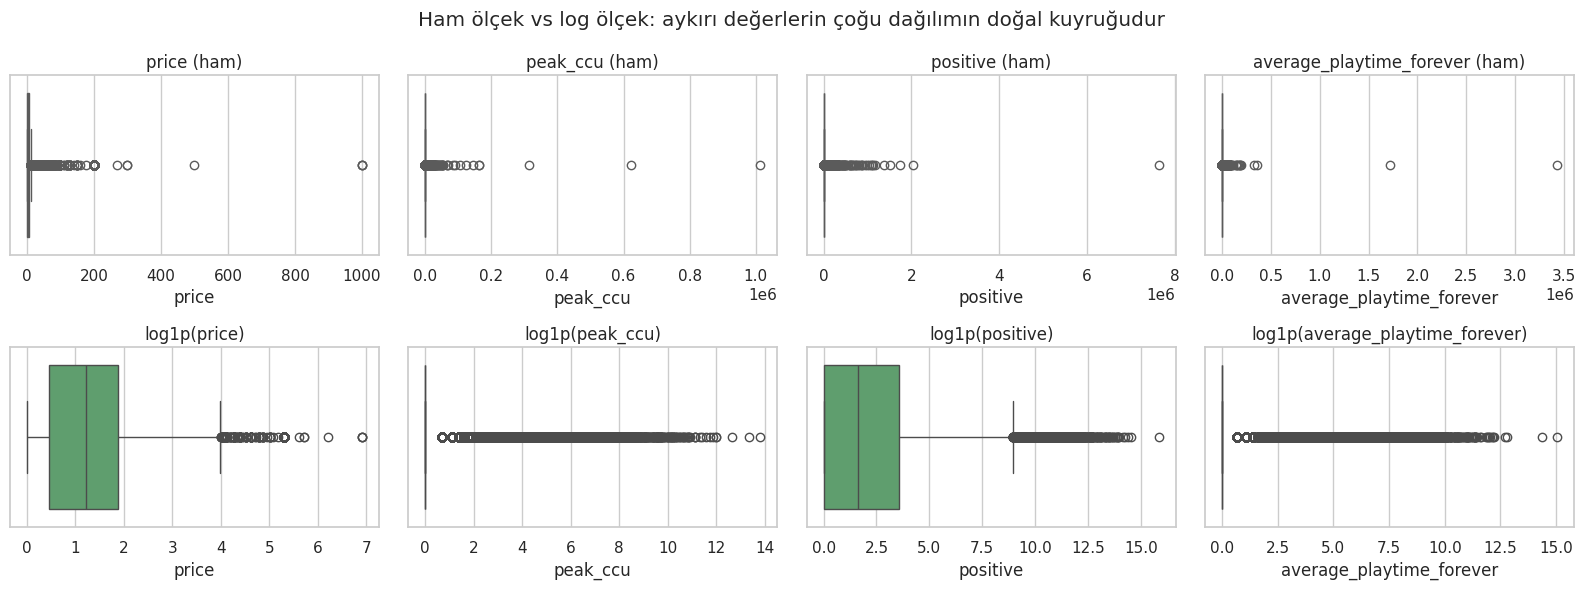

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, c in zip(axes[0], ["price", "peak_ccu", "positive", "average_playtime_forever"]):
    sns.boxplot(x=clean[c], ax=ax, color="#DD8452"); ax.set_title(f"{c} (ham)")
for ax, c in zip(axes[1], ["price", "peak_ccu", "positive", "average_playtime_forever"]):
    sns.boxplot(x=np.log1p(clean[c]), ax=ax, color="#55A868"); ax.set_title(f"log1p({c})")
plt.suptitle("Ham ölçek vs log ölçek: aykırı değerlerin çoğu dağılımın doğal kuyruğudur")
plt.tight_layout(); plt.show()

In [20]:
# Alan bilgisine dayalı "makul olmayan" (muhtemel hata) kuralları
implausible = {
    "Fiyat > 500 $": clean["price"] > 500,
    "Ortalama oynanma > 20.000 saat": clean["average_playtime_forever"] > 20000 * 60,
    "Achievements > 5000": clean["achievements"] > 5000,
    "DLC > 1000": clean["dlc_count"] > 1000,
}
for k, m in implausible.items():
    print(f"{k:35s}: {m.sum()} satır")
clean["is_implausible"] = np.column_stack(list(implausible.values())).any(axis=1).astype(int)

suspect = clean.loc[clean["is_implausible"] == 1, ["name", "price", "average_playtime_forever", "achievements", "dlc_count"]]
suspect.head(10)

Fiyat > 500 $                      : 3 satır
Ortalama oynanma > 20.000 saat     : 2 satır
Achievements > 5000                : 2 satır
DLC > 1000                         : 3 satır


,name,price,average_playtime_forever,achievements,dlc_count
8313,Drive-By Hero,3.49,34,5394,0
27968,Avem33,0.00,3429544,0,0
34463,Ascent Free-Roaming VR Experience,999.00,0,0,0
41088,The Leverage Game Business Edition,999.98,0,0,0
59930,iTownGamePlay UNIVERSE,0.00,1714275,13,2
68275,The Leverage Game,999.98,0,0,0
76082,LOGistICAL,3.99,9448,9821,7
81495,Fantasy Grounds Classic,0.00,1379,0,2006
97884,RPG Maker MV,11.99,3040,0,1066
122448,Fantasy Grounds VTT,0.00,8630,0,3703


In [21]:
# Karar: Muhtemel hatalı değerler NaN yapılır (sonra impute edilir),
# gerçek ağır kuyruk ise log dönüşümü ile yönetilir (Bölüm 7).
clean.loc[clean["price"] > 500, "price"] = np.nan
clean.loc[clean["average_playtime_forever"] > 20000 * 60, "average_playtime_forever"] = np.nan
clean.loc[clean["achievements"] > 5000, "achievements"] = np.nan

# Alternatif yöntem gösterimi: 1.-99. yüzdelik ile winsorizing (kırpma)
lo, hi = clean["price"].quantile([0.01, 0.99])
clean["price_winsor"] = clean["price"].clip(lo, hi)
print(f"Winsorize sınırları (price): {lo:.2f} - {hi:.2f}")
clean[["price", "price_winsor"]].describe().T

Winsorize sınırları (price): 0.00 - 29.99


,count,mean,std,min,25%,50%,75%,max
price,125851.0,4.787498,11.506299,0.0,0.59,2.39,5.52,500.00
price_winsor,125851.0,4.247918,5.483984,0.0,0.59,2.39,5.52,29.99


---
## 6. Tekrarlı, Tutarsız ve Gürültülü Veri (Duplicate, Inconsistent, Noisy)

- **Tekrarlı:** Aynı oyunun birden fazla kez kaydedilmesi
- **Tutarsız:** Mantıksal olarak çelişen alanlar, farklı yazımlar ("Valve" / "valve ")
- **Gürültülü:** Analiz amacına uymayan kayıtlar (playtest/demo), birim farkları

In [22]:
# 6.1 Tekrarlar
print("Tam tekrar satır       :", clean.drop(columns=[c for c in clean.columns if c.endswith("_list")]).duplicated().sum())
print("Tekrarlı AppID         :", clean["appid"].duplicated().sum())

# Aynı isim + aynı tarih + aynı geliştirici => aynı oyunun farklı AppID ile kaydı olabilir
key = ["name", "release_date", "developers"]
dup_mask = clean.duplicated(subset=key, keep=False)
print("Aynı isim+tarih+geliştirici:", dup_mask.sum())
clean.loc[dup_mask, ["appid"] + key].sort_values("name").head(10)

Tam tekrar satır       : 0
Tekrarlı AppID         : 0
Aynı isim+tarih+geliştirici: 181


,appid,name,release_date,developers
108996,34019,Alpha Protocol™,2010-06-01,Obsidian Entertainment
78035,34010,Alpha Protocol™,2010-06-01,Obsidian Entertainment
63287,33230,Assassin's Creed 2,2010-03-09,Ubisoft Montreal
83437,48173,Assassin's Creed 2,2010-03-09,Ubisoft Montreal
73217,22350,BRINK,2011-05-09,Splash Damage
73810,22360,BRINK,2011-05-09,Splash Damage
118704,22362,BRINK,2011-05-09,Splash Damage
39442,35010,Batman: Arkham Asylum Game of the Year Edition,2010-03-26,Rocksteady Studios
25868,35140,Batman: Arkham Asylum Game of the Year Edition,2010-03-26,Rocksteady Studios
70093,209650,Call of Duty®: Advanced Warfare - Gold Edition,2014-11-03,"Sledgehammer Games,Raven Software"


In [23]:
n_before = len(clean)
clean = clean.drop_duplicates(subset="appid", keep="first")
clean = clean.drop_duplicates(subset=key, keep="first")
print(f"Tekrarlar silindi: {n_before - len(clean)} satır")

Tekrarlar silindi: 111 satır


In [24]:
# 6.2 Tutarsız yazımlar: geliştirici adları
def canonical(name):
    if pd.isna(name):
        return name
    n = str(name).casefold()
    n = re.sub(r"[.,]|\b(inc|ltd|llc|co|corp|gmbh|studios?|games?)\b", "", n)
    return re.sub(r"\s+", " ", n).strip()

dev_first = clean["developers_list"].map(lambda l: l[0] if len(l) else np.nan)
variants = (pd.DataFrame({"orijinal": dev_first, "kanonik": dev_first.map(canonical)})
              .dropna().drop_duplicates()
              .groupby("kanonik")["orijinal"].agg(lambda x: sorted(set(x))))
variants = variants[variants.str.len() > 1]
print(f"Farklı yazımla görünen geliştirici sayısı: {len(variants)}")
variants.head(10)

Farklı yazımla görünen geliştirici sayısı: 1996


,orijinal
kanonik,
,"[., GAME Games, Game, Game Game Games, Game St..."
01,"[01 Games, 01 Studio]"
1bit,"[1bit, 1bit Games]"
1up,"[1UP Games, 1UP games]"
21cducks,"[21c.Ducks Co., 21cDucks co.]"
2pi interactivee pvt,"[2Pi Interactivee Pvt. Ltd, 2Pi Interactivee P..."
3xentertainment,"[3XEntertainment, 3xentertainment]"
3z,"[3Z, 3z Studios]"
4 fun,"[4 Fun Studio, 4 Fun Studio Inc.]"


In [25]:
clean["main_developer"] = dev_first.map(canonical)
clean["main_publisher"] = clean["publishers_list"].map(lambda l: canonical(l[0]) if len(l) else "unknown")
clean["main_developer"] = clean["main_developer"].fillna("unknown")

# 6.3 Mantıksal tutarsızlıkların düzeltilmesi
m = clean["average_playtime_two_weeks"] > clean["average_playtime_forever"]
print("2 hafta > toplam (düzeltildi):", m.sum())
clean.loc[m, "average_playtime_two_weeks"] = clean.loc[m, "average_playtime_forever"]

m = (clean["price"] == 0) & (clean["discount"] > 0)
print("Ücretsiz oyunda indirim (0'a çekildi):", m.sum())
clean.loc[m, "discount"] = 0

clean["is_self_published"] = (clean["main_developer"] == clean["main_publisher"]).astype(int)

2 hafta > toplam (düzeltildi): 366
Ücretsiz oyunda indirim (0'a çekildi): 37


In [26]:
# 6.4 Birim tutarlılığı: oynanma süreleri dakika -> saat
pt_cols = ["average_playtime_forever", "average_playtime_two_weeks",
           "median_playtime_forever", "median_playtime_two_weeks"]
for c in pt_cols:
    clean[c.replace("playtime", "hours")] = clean[c] / 60
clean = clean.drop(columns=pt_cols)

# 6.5 Gürültü: playtest / demo / test sürümleri gerçek "oyun" değildir
noise_pat = r"\b(playtest|demo|test server|beta test|soundtrack|ost)\b"
clean["is_noise"] = clean["name"].str.contains(noise_pat, case=False, regex=True).astype(int)
print("Playtest/Demo/Soundtrack kaydı:", clean["is_noise"].sum())
print(clean.loc[clean["is_noise"] == 1, "name"].head(10).tolist())

n_before = len(clean)
clean = clean[clean["is_noise"] == 0].drop(columns="is_noise")
print(f"Gürültülü kayıtlar silindi: {n_before - len(clean)} | Kalan satır: {len(clean)}")

Playtest/Demo/Soundtrack kaydı: 8222
['Black Dragon Mage Playtest', 'Codename: Warlock Playtest', 'CyberVault Playtest', "A Night In Omar's Burger Playtest", 'Dark and Deep Playtest', "Bill's Misfortune Playtest", 'QUADRA CLASH Playtest', 'Descendance Playtest', 'Red Solstice 2: Survivors Playtest', 'Pain Party Playtest']
Gürültülü kayıtlar silindi: 8222 | Kalan satır: 117521


---
## 7. Veri Dönüşümü, Ölçekleme ve Normalizasyon

Mesafe tabanlı (KNN, SVM) ve gradyan tabanlı (lojistik regresyon, sinir ağları) modeller, değişkenlerin ölçeğinden doğrudan etkilenir. `price` (0–100) ile `peak_ccu` (0–1.000.000) aynı modelde ölçeklenmeden kullanılırsa büyük ölçekli değişken baskın olur.

**Strateji:**
1. Çarpık sayım değişkenleri için önce **log1p** (ya da Yeo-Johnson) → dağılımı simetrikleştir
2. Ardından **ölçekleme** → aynı aralığa getir

In [27]:
skewed_cols = ["price", "peak_ccu", "positive", "negative", "recommendations",
               "dlc_count", "achievements", "average_hours_forever", "owners_mid", "n_screenshots"]
skewed_cols = [c for c in skewed_cols if c in clean.columns]

skew_table = pd.DataFrame({
    "Ham çarpıklık": clean[skewed_cols].skew(),
    "log1p sonrası": np.log1p(clean[skewed_cols]).skew(),
})
pt = PowerTransformer(method="yeo-johnson")
yj = pt.fit_transform(clean[skewed_cols].fillna(clean[skewed_cols].median()))
skew_table["Yeo-Johnson sonrası"] = pd.DataFrame(yj, columns=skewed_cols).skew().values
skew_table.round(2)

,Ham çarpıklık,log1p sonrası,Yeo-Johnson sonrası
price,12.72,0.41,0.03
peak_ccu,206.33,4.34,1.82
positive,178.87,1.05,0.21
negative,157.69,1.41,0.39
recommendations,125.86,1.98,1.68
dlc_count,189.54,4.16,1.93
achievements,31.35,0.32,0.13
average_hours_forever,74.05,2.78,1.49
owners_mid,70.96,-1.63,0.21
n_screenshots,4.64,0.87,-0.21


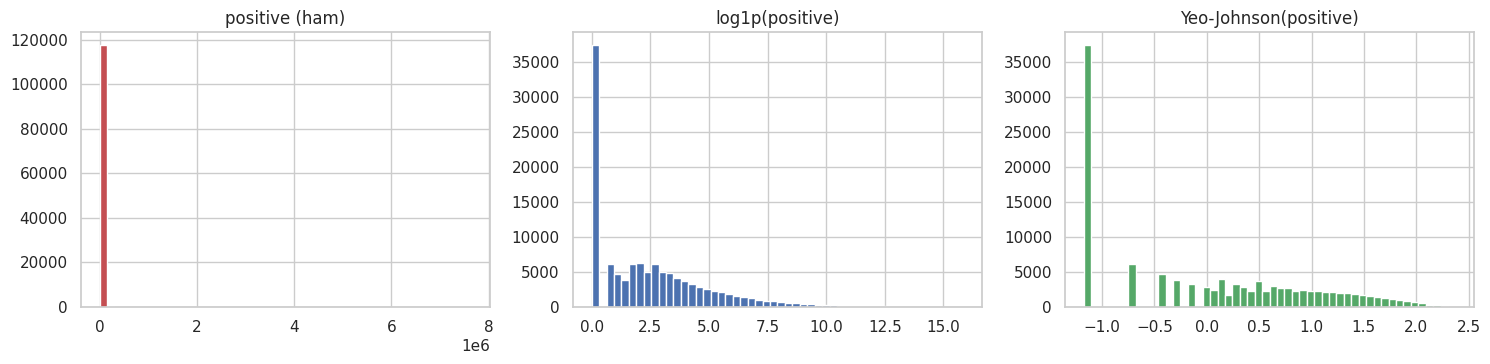

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
s = clean["positive"].dropna()
axes[0].hist(s, bins=50, color="#C44E52"); axes[0].set_title("positive (ham)")
axes[1].hist(np.log1p(s), bins=50, color="#4C72B0"); axes[1].set_title("log1p(positive)")
axes[2].hist(PowerTransformer().fit_transform(s.to_frame()).ravel(), bins=50, color="#55A868")
axes[2].set_title("Yeo-Johnson(positive)")
plt.tight_layout(); plt.show()

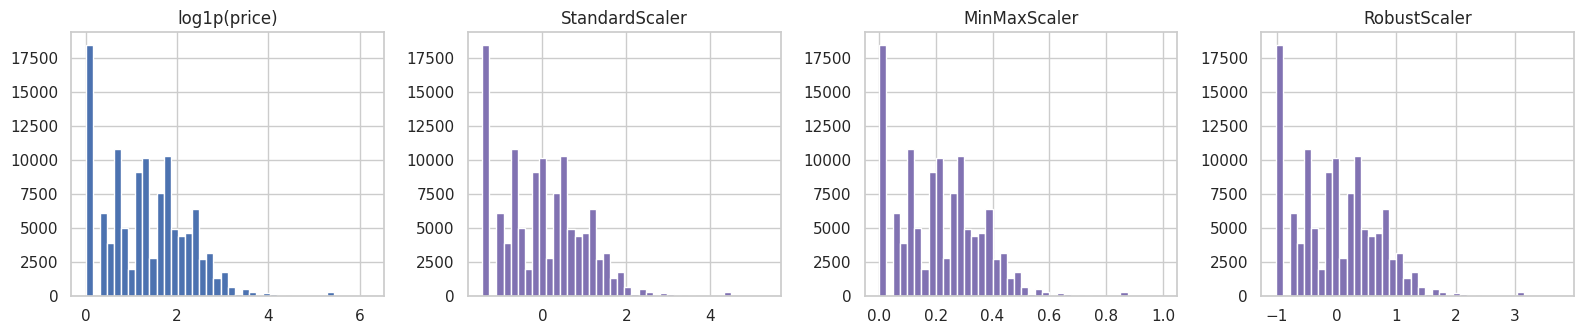

,Orijinal log1p(price),StandardScaler,MinMaxScaler,RobustScaler
count,117518.000,117518.000,117518.000,117518.000
mean,1.319,-0.000,0.212,-0.011
std,0.918,1.000,0.148,0.705
min,0.000,-1.437,0.000,-1.023
25%,0.642,-0.737,0.103,-0.530
50%,1.332,0.015,0.214,0.000
75%,1.944,0.682,0.313,0.470
max,6.217,5.336,1.000,3.750


In [29]:
# Ölçekleyicilerin karşılaştırılması (log(price) üzerinde)
x = np.log1p(clean[["price"]].dropna())
scalers = {"StandardScaler": StandardScaler(), "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}
res = {"Orijinal log1p(price)": x["price"].describe()}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
axes[0].hist(x["price"], bins=40); axes[0].set_title("log1p(price)")
for ax, (name, sc) in zip(axes[1:], scalers.items()):
    v = sc.fit_transform(x).ravel()
    res[name] = pd.Series(v).describe()
    ax.hist(v, bins=40, color="#8172B2"); ax.set_title(name)
plt.tight_layout(); plt.show()
pd.DataFrame(res).round(3)

| Yöntem | Formül | Ne zaman? |
|---|---|---|
| **StandardScaler** | (x − μ) / σ | Yaklaşık normal dağılım; lojistik regresyon, SVM, PCA |
| **MinMaxScaler** | (x − min) / (max − min) | Sınırlı aralık gerektiğinde (sinir ağları); aykırı değere duyarlı |
| **RobustScaler** | (x − medyan) / IQR | Aykırı değer varken |
| **log1p / Yeo-Johnson** | — | Sağa çarpık sayım ve parasal değişkenler |

**Bu çalışmadaki seçim:** Çarpık değişkenlere `log1p`, ardından `StandardScaler`. Ağaç tabanlı modeller ölçeklemeye ihtiyaç duymaz, ancak karşılaştırma için tek pipeline kullanılmıştır. Ölçekleyiciler yalnızca **eğitim verisine fit edilecektir** (Bölüm 10).

In [30]:
# log dönüşümleri kalıcı özellik olarak eklenir (bu dönüşüm satır bazlıdır, sızıntı yaratmaz)
for c in skewed_cols:
    clean["log_" + c] = np.log1p(clean[c])
clean[[c for c in clean.columns if c.startswith("log_")]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
log_price,117518.0,1.32,0.92,0.0,0.64,1.33,1.94,6.22
log_peak_ccu,117521.0,0.35,1.06,0.0,0.00,0.00,0.00,13.83
log_positive,117521.0,2.36,2.40,0.0,0.00,1.95,3.71,15.85
log_negative,117521.0,1.53,1.91,0.0,0.00,0.69,2.48,13.98
log_recommendations,117521.0,1.14,2.54,0.0,0.00,0.00,0.00,15.39
log_dlc_count,117521.0,0.16,0.44,0.0,0.00,0.00,0.00,8.22
log_achievements,117519.0,1.60,1.61,0.0,0.00,1.79,3.04,8.52
log_average_hours_forever,117519.0,0.36,0.85,0.0,0.00,0.00,0.00,8.70
log_owners_mid,117521.0,8.41,3.55,0.0,9.21,9.21,9.21,18.83
log_n_screenshots,117521.0,2.19,0.41,0.0,1.79,2.08,2.40,5.21


---
## 8. Keşifsel Veri Analizi (EDA) ve Görselleştirme

Model kurmadan önce dağılımları, ilişkileri, dengesizlikleri ve olası sorunları keşfediyoruz.

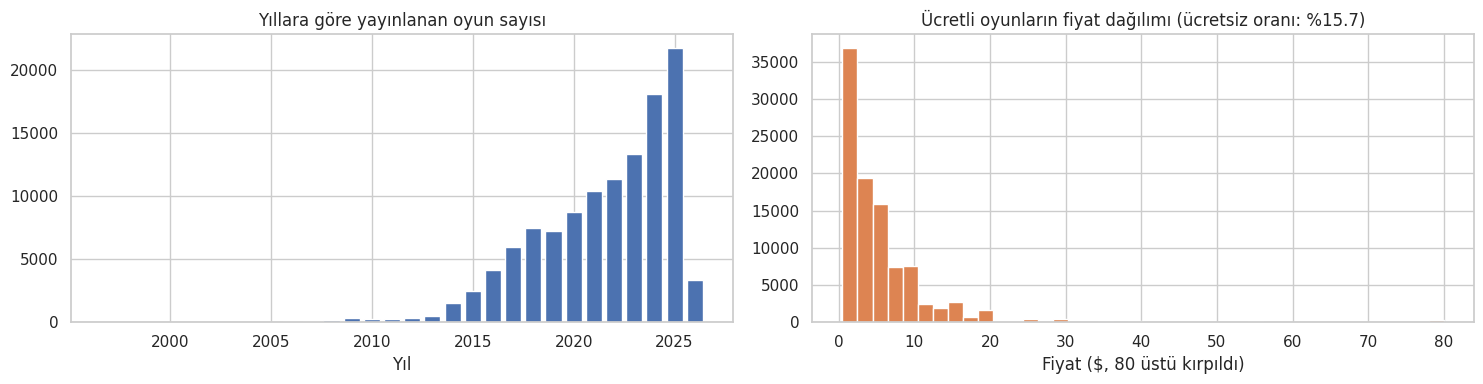

In [31]:
clean["release_year"] = clean["release_date"].dt.year
year_counts = clean["release_year"].value_counts().sort_index()
year_counts = year_counts[year_counts.index >= 1997]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].bar(year_counts.index, year_counts.values, color="#4C72B0")
axes[0].set_title("Yıllara göre yayınlanan oyun sayısı"); axes[0].set_xlabel("Yıl")
free_ratio = (clean["price"] == 0).mean()
axes[1].hist(clean.loc[clean["price"] > 0, "price"].clip(upper=80), bins=40, color="#DD8452")
axes[1].set_title(f"Ücretli oyunların fiyat dağılımı (ücretsiz oranı: %{free_ratio*100:.1f})")
axes[1].set_xlabel("Fiyat ($, 80 üstü kırpıldı)")
plt.tight_layout(); plt.show()

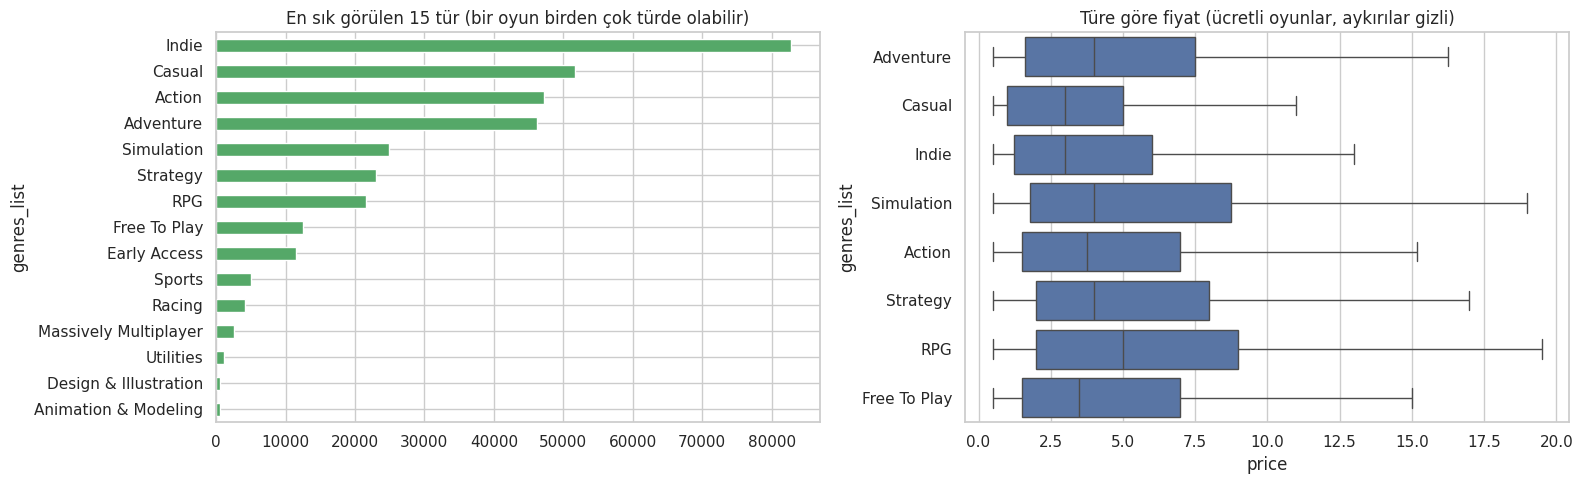

In [32]:
genres_exploded = clean[["appid", "genres_list", "price", "log_positive"]].explode("genres_list").dropna(subset=["genres_list"])
top_genres = genres_exploded["genres_list"].value_counts().head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
top_genres.sort_values().plot.barh(ax=axes[0], color="#55A868")
axes[0].set_title("En sık görülen 15 tür (bir oyun birden çok türde olabilir)")
g = genres_exploded[genres_exploded["genres_list"].isin(top_genres.index[:8])]
sns.boxplot(data=g[g["price"] > 0], x="price", y="genres_list", ax=axes[1], showfliers=False)
axes[1].set_title("Türe göre fiyat (ücretli oyunlar, aykırılar gizli)")
plt.tight_layout(); plt.show()

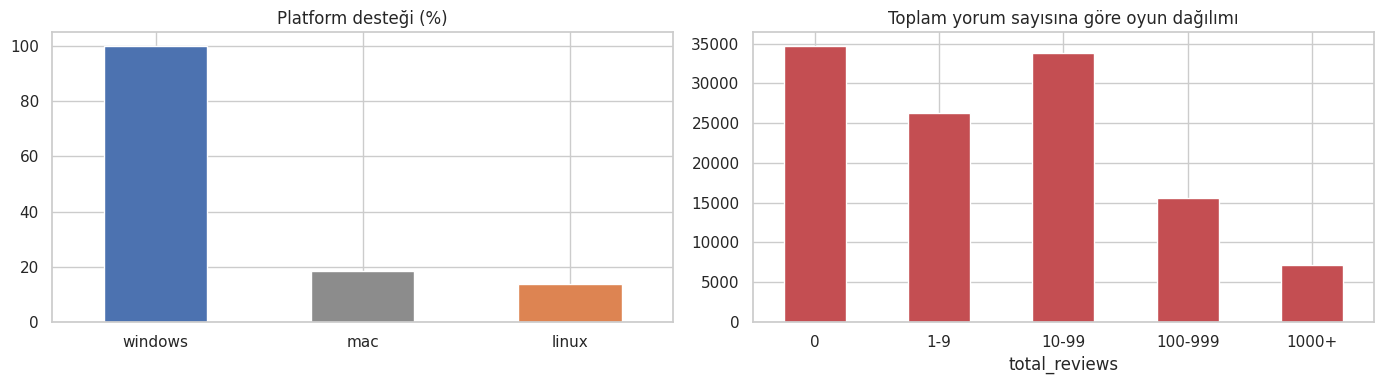

Hiç yorumu olmayan oyun oranı: %29.5


In [33]:
platforms = clean[["windows", "mac", "linux"]].mean().mul(100)
reviews_dist = pd.cut(clean["total_reviews"], [-1, 0, 9, 99, 999, np.inf],
                      labels=["0", "1-9", "10-99", "100-999", "1000+"]).value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
platforms.plot.bar(ax=axes[0], color=["#4C72B0", "#8C8C8C", "#DD8452"], rot=0)
axes[0].set_title("Platform desteği (%)")
reviews_dist.plot.bar(ax=axes[1], color="#C44E52", rot=0)
axes[1].set_title("Toplam yorum sayısına göre oyun dağılımı")
plt.tight_layout(); plt.show()
print("Hiç yorumu olmayan oyun oranı: %{:.1f}".format((clean["total_reviews"] == 0).mean() * 100))

**Önemli bulgu:** Oyunların büyük çoğunluğu çok az yorum almıştır. Az yorumlu bir oyunun "olumlu oranı" güvenilir değildir (2 yorumun 2'si olumlu = %100). Bu yüzden hedef değişken tanımlanırken **minimum yorum eşiği** (≥ 10) uygulanacaktır.

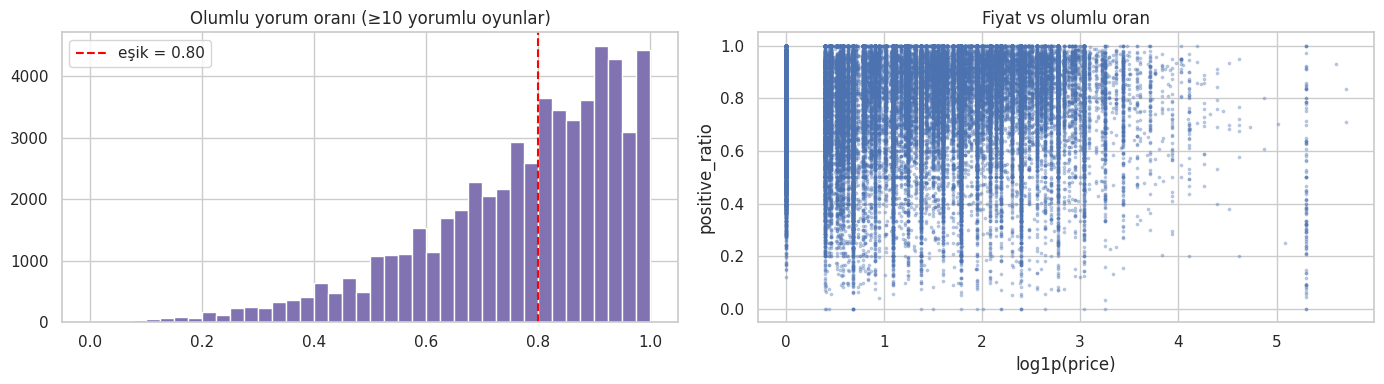

In [34]:
clean["positive_ratio"] = np.where(clean["total_reviews"] > 0,
                                   clean["positive"] / clean["total_reviews"], np.nan)
reliable = clean[clean["total_reviews"] >= 10]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(reliable["positive_ratio"], bins=40, color="#8172B2")
axes[0].axvline(0.8, color="red", ls="--", label="eşik = 0.80")
axes[0].set_title("Olumlu yorum oranı (≥10 yorumlu oyunlar)"); axes[0].legend()
axes[1].scatter(reliable["log_price"], reliable["positive_ratio"], s=3, alpha=0.3)
axes[1].set_xlabel("log1p(price)"); axes[1].set_ylabel("positive_ratio")
axes[1].set_title("Fiyat vs olumlu oran")
plt.tight_layout(); plt.show()

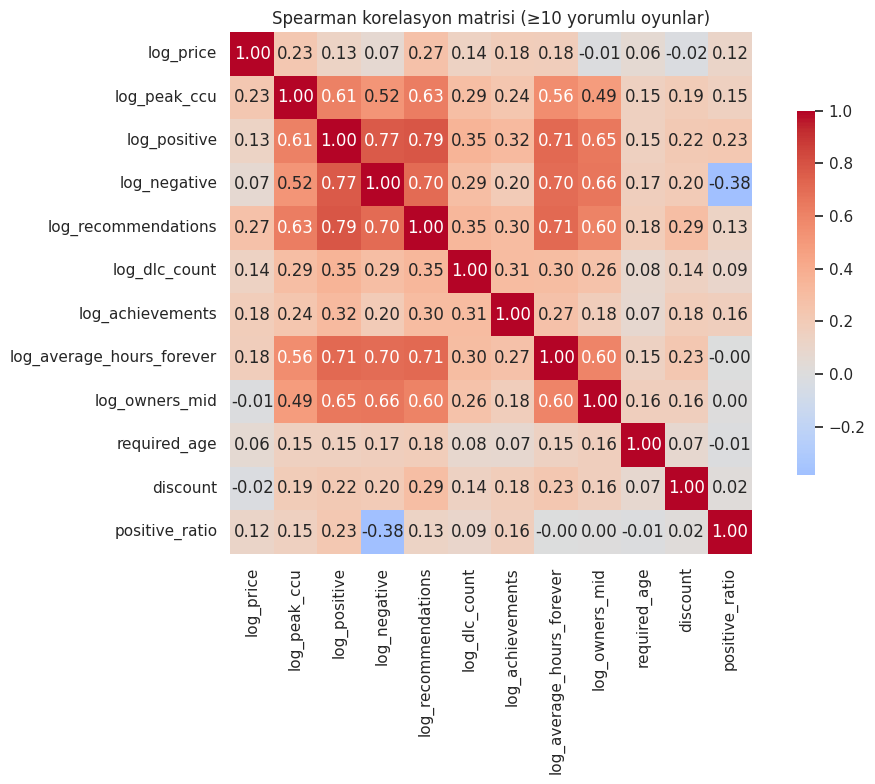

In [35]:
corr_cols = ["log_price", "log_peak_ccu", "log_positive", "log_negative", "log_recommendations",
             "log_dlc_count", "log_achievements", "log_average_hours_forever", "log_owners_mid",
             "metacritic_score", "required_age", "discount", "positive_ratio"]
corr_cols = [c for c in corr_cols if c in clean.columns]
corr = reliable[corr_cols].corr(method="spearman")
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.7})
plt.title("Spearman korelasyon matrisi (≥10 yorumlu oyunlar)")
plt.tight_layout(); plt.show()

**EDA'dan çıkan sonuçlar:**
- Steam'e eklenen oyun sayısı son yıllarda hızla artmıştır → zamana bağlı dağılım kayması (drift) olabilir.
- Fiyat, yorum sayısı, sahip sayısı aşırı çarpıktır → log dönüşümü gereklidir (Bölüm 7 ile tutarlı).
- `positive`, `negative`, `recommendations`, `peak_ccu`, `owners` birbirleriyle çok güçlü korelelidir → hepsi "popülerlik" kavramını ölçer (çoklu doğrusallık).
- Olumlu oran dağılımı sola çarpıktır; 0.80 eşiğinde sınıflar arasında **dengesizlik** olup olmadığı Bölüm 10'da kontrol edilecektir.

---
## 9. Özellik Mühendisliği ve Özellik Seçimi (Feature Engineering & Selection)

Ham değişkenleri model için anlamlı temsillere dönüştürüyoruz. Senaryo: **"Bir oyunun mağaza sayfası bilgilerine bakarak, oyuncular tarafından beğenilip beğenilmeyeceğini tahmin et."**

In [36]:
fe = clean.copy()

# Zaman özellikleri
fe["release_month"] = fe["release_date"].dt.month
fe["game_age_years"] = (snapshot_date - fe["release_date"]).dt.days / 365.25

# Dil özellikleri
fe["n_languages"] = fe["languages_list"].str.len()
fe["n_audio_languages"] = fe["audio_languages_list"].str.len()
fe["has_turkish"] = fe["languages_list"].map(lambda l: int("Turkish" in l))

# Etiket / tür / kategori sayıları
fe["n_genres"] = fe["genres_list"].str.len()
fe["n_tags"] = fe["tags_list"].str.len()
fe["n_categories"] = fe["categories_list"].str.len()

# İçerik ve ticari özellikler
fe["description_len"] = fe["about_the_game"].fillna("").str.len()
fe["log_description_len"] = np.log1p(fe["description_len"])
fe["is_free"] = (fe["price"] == 0).astype(int)
fe["has_dlc"] = (fe["dlc_count"] > 0).astype(int)
fe["n_platforms"] = fe[["windows", "mac", "linux"]].sum(axis=1)
for c in ["windows", "mac", "linux"]:
    fe[c] = fe[c].astype(int)

# Kategori bayrakları
cat_flags = {"Single-player": "is_singleplayer", "Multi-player": "is_multiplayer",
             "Steam Achievements": "has_achievements_cat", "Steam Cloud": "has_cloud",
             "Full controller support": "has_controller", "Steam Trading Cards": "has_trading_cards",
             "Steam Workshop": "has_workshop", "VR Only": "is_vr_only"}
for cat, col in cat_flags.items():
    fe[col] = fe["categories_list"].map(lambda l, cat=cat: int(cat in l))

# Tür multi-hot kodlama (en sık 15 tür)
genre_counts = fe["genres_list"].explode().value_counts()
top_k = list(genre_counts.head(15).index)
mlb = MultiLabelBinarizer(classes=top_k)
genre_ohe = pd.DataFrame(mlb.fit_transform(fe["genres_list"].map(lambda l: [g for g in l if g in top_k])),
                         columns=["genre_" + re.sub(r"\W+", "_", g).lower() for g in top_k], index=fe.index)
fe = pd.concat([fe, genre_ohe], axis=1)

# Yüksek kardinaliteli geliştirici -> frekans kodlama (oyun sayısı = stüdyo deneyimi)
fe["developer_game_count"] = fe["main_developer"].map(fe["main_developer"].value_counts())
fe["log_developer_game_count"] = np.log1p(fe["developer_game_count"])

new_feats = ["release_year", "release_month", "game_age_years", "n_languages", "n_audio_languages",
             "has_turkish", "n_genres", "n_tags", "n_categories", "log_description_len", "is_free",
             "has_dlc", "n_platforms", "log_developer_game_count", "is_self_published"] + list(cat_flags.values()) + list(genre_ohe.columns)
print(f"Türetilen yeni özellik sayısı: {len(new_feats)}")
fe[new_feats].head()

Türetilen yeni özellik sayısı: 38


,release_year,release_month,game_age_years,n_languages,n_audio_languages,has_turkish,n_genres,n_tags,n_categories,log_description_len,is_free,has_dlc,n_platforms,log_developer_game_count,is_self_published,is_singleplayer,is_multiplayer,has_achievements_cat,has_cloud,has_controller,has_trading_cards,has_workshop,is_vr_only,genre_indie,genre_casual,genre_action,genre_adventure,genre_simulation,genre_strategy,genre_rpg,genre_free_to_play,genre_early_access,genre_sports,genre_racing,genre_massively_multiplayer,genre_utilities,genre_design_illustration,genre_animation_modeling
1,2016,7,10.203970,1,0,0,1,4,4,7.394493,0,0,1,2.197225,0,1,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
2,2019,5,7.436003,4,0,0,1,16,2,7.072422,0,0,2,4.262680,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
3,2024,10,1.946612,1,1,0,3,0,3,7.510978,0,1,1,2.639057,1,1,0,1,0,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0
4,2025,4,1.467488,1,1,0,2,0,4,7.302496,0,0,1,1.098612,1,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0
5,2023,4,3.520876,9,2,1,2,0,4,7.514800,0,0,1,1.791759,1,1,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0


### 9.1 Hedef değişkenin tanımı
`high_rating = 1` ⇔ olumlu yorum oranı ≥ 0.80. Yalnızca **en az 10 yorum** almış oyunlar modele dahil edilir (güvenilir etiket).

In [37]:
model_df = fe[fe["total_reviews"] >= 10].copy()
model_df["high_rating"] = (model_df["positive_ratio"] >= 0.80).astype(int)
print("Modellenebilir satır sayısı:", len(model_df))
print("Sınıf dağılımı (%):")
print(model_df["high_rating"].value_counts(normalize=True).mul(100).round(1))

Modellenebilir satır sayısı: 56544
Sınıf dağılımı (%):
high_rating
1    53.5
0    46.5
Name: proportion, dtype: float64


In [38]:
# Pre-release (sızıntısız) aday özellikler
candidate_features = ["log_price", "discount", "required_age", "log_dlc_count", "log_achievements",
                      "log_n_screenshots", "n_movies", "has_website", "has_support_contact",
                      "has_content_notes", "windows", "mac", "linux"] + new_feats
candidate_features = [c for c in dict.fromkeys(candidate_features) if c in model_df.columns]
X_all = model_df[candidate_features].astype(float)
y_all = model_df["high_rating"]

# Yöntem 1: Varyans eşiği (neredeyse sabit özellikler)
vt_sel = VarianceThreshold(threshold=0.01)
vt_sel.fit(X_all.fillna(X_all.median()))
low_var = [c for c, keep in zip(candidate_features, vt_sel.get_support()) if not keep]
print("Düşük varyanslı (atılan):", low_var)

# Yöntem 2: Yüksek korelasyon filtresi (|r| > 0.90)
feats = [c for c in candidate_features if c not in low_var]
cm = X_all[feats].corr().abs()
upper = cm.where(np.triu(np.ones(cm.shape), k=1).astype(bool))
high_corr = [c for c in upper.columns if (upper[c] > 0.90).any()]
print("Yüksek korelasyonlu (atılan):", high_corr)
feats = [c for c in feats if c not in high_corr]
print("Kalan özellik sayısı:", len(feats))

Düşük varyanslı (atılan): ['n_movies', 'windows', 'genre_utilities', 'genre_design_illustration', 'genre_animation_modeling']
Yüksek korelasyonlu (atılan): ['game_age_years', 'n_platforms']
Kalan özellik sayısı: 44


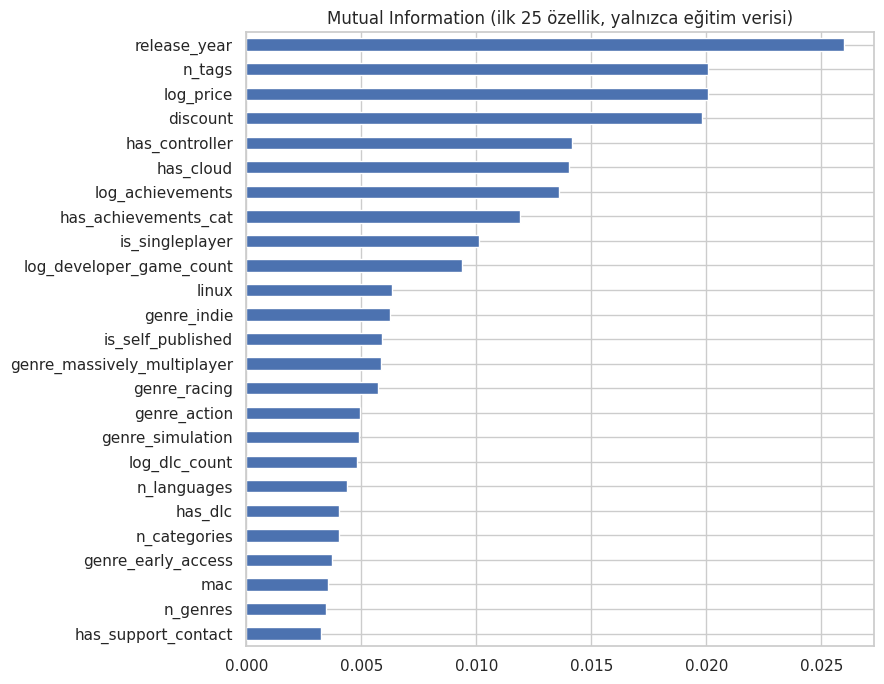

Seçilen özellik sayısı: 41


In [39]:
# Yöntem 3: Karşılıklı bilgi (Mutual Information) - hedefle ilişki
can_model = len(model_df) >= 50 and y_all.nunique() == 2 and y_all.value_counts().min() >= 10
if can_model:
    # Sızıntı olmaması için MI yalnızca eğitim bölümünde hesaplanır
    X_tmp, _, y_tmp, _ = train_test_split(X_all[feats], y_all, test_size=0.2,
                                          stratify=y_all, random_state=RANDOM_STATE)
    mi = mutual_info_classif(X_tmp.fillna(X_tmp.median()), y_tmp, random_state=RANDOM_STATE)
    mi = pd.Series(mi, index=feats).sort_values(ascending=False)
    plt.figure(figsize=(9, 7)); mi.head(25).sort_values().plot.barh(color="#4C72B0")
    plt.title("Mutual Information (ilk 25 özellik, yalnızca eğitim verisi)"); plt.tight_layout(); plt.show()
    selected_features = list(mi[mi > 0].index) or feats
else:
    print("Veri çok küçük ya da tek sınıflı: MI hesabı atlandı (tam games.csv ile çalıştırın).")
    selected_features = feats
print("Seçilen özellik sayısı:", len(selected_features))

---
## 10. ML'e Hazır Veri Seti ve Data Leakage (Veri Sızıntısı)

**Veri sızıntısı:** Modelin eğitimi sırasında, tahmin anında gerçekte erişilemeyecek bilgiye erişmesidir. Sonuç: eğitim/test başarısı yüksek, gerçek hayatta model başarısız.

Bu veri setindeki iki sızıntı türü:

**(a) Hedef sızıntısı (target leakage):** Hedef, `positive` ve `negative`'den türetildi. Bu kolonlar ve onlarla birlikte oluşan değişkenler (`recommendations`, `user_score`, `peak_ccu`, `owners`, oynanma süreleri, `metacritic_score`) oyun **yayınlandıktan sonra** ortaya çıkar. Senaryomuz "yayın öncesi tahmin" olduğu için bunlar modele girmemelidir.

**(b) Ön işleme sızıntısı (train-test contamination):** Medyan doldurma ve ölçekleme **tüm veri** üzerinde fit edilirse, test setinin istatistikleri eğitime sızar. Çözüm: `train_test_split` → `Pipeline` → sadece `X_train` üzerinde `fit`.

In [40]:
leaky_features = ["log_positive", "log_negative", "log_recommendations", "log_peak_ccu",
                  "log_owners_mid", "log_average_hours_forever", "metacritic_score", "has_metacritic",
                  "user_score", "total_reviews", "positive_ratio"]
leaky_features = [c for c in leaky_features if c in model_df.columns]
assert not set(leaky_features) & set(selected_features), "Sızıntılı özellik seçilen listede!"
pd.DataFrame({"Sızıntılı özellik": leaky_features,
              "Neden": ["Yayın sonrası oluşur / hedefle aynı kaynaktan türetilir"] * len(leaky_features)})

,Sızıntılı özellik,Neden
0,log_positive,Yayın sonrası oluşur / hedefle aynı kaynaktan ...
1,log_negative,Yayın sonrası oluşur / hedefle aynı kaynaktan ...
2,log_recommendations,Yayın sonrası oluşur / hedefle aynı kaynaktan ...
3,log_peak_ccu,Yayın sonrası oluşur / hedefle aynı kaynaktan ...
4,log_owners_mid,Yayın sonrası oluşur / hedefle aynı kaynaktan ...
5,log_average_hours_forever,Yayın sonrası oluşur / hedefle aynı kaynaktan ...
6,has_metacritic,Yayın sonrası oluşur / hedefle aynı kaynaktan ...
7,total_reviews,Yayın sonrası oluşur / hedefle aynı kaynaktan ...
8,positive_ratio,Yayın sonrası oluşur / hedefle aynı kaynaktan ...


In [41]:
def make_pipeline(model):
    pre = ColumnTransformer([("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),   # medyan sadece train'den
        ("scaler", StandardScaler()),                    # ortalama/std sadece train'den
    ]), slice(0, None))])
    return Pipeline([("pre", pre), ("model", model)])

if can_model:
    X = model_df[selected_features].astype(float)
    X_leaky = model_df[selected_features + leaky_features].astype(float)
    idx_train, idx_test = train_test_split(model_df.index, test_size=0.2, stratify=y_all,
                                           random_state=RANDOM_STATE)
    y_train, y_test = y_all.loc[idx_train], y_all.loc[idx_test]
    print(f"Eğitim: {len(idx_train)} | Test: {len(idx_test)}")
    print("Eğitim sınıf oranı:", y_train.mean().round(3), "| Test sınıf oranı:", y_test.mean().round(3))
else:
    print("Model eğitimi için yeterli veri yok; tam games.csv ile çalıştırın.")

Eğitim: 45235 | Test: 11309
Eğitim sınıf oranı: 0.535 | Test sınıf oranı: 0.535


In [42]:
results = []
if can_model:
    models = {
        "LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced"),
        "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1,
                                               class_weight="balanced", random_state=RANDOM_STATE),
    }
    for name, mdl in models.items():
        for setting, data in [("Temiz (sızıntısız)", X), ("Sızıntılı", X_leaky)]:
            pipe = make_pipeline(mdl)
            pipe.fit(data.loc[idx_train], y_train)
            proba = pipe.predict_proba(data.loc[idx_test])[:, 1]
            pred = (proba >= 0.5).astype(int)
            results.append({"Model": name, "Özellik seti": setting,
                            "ROC-AUC": round(roc_auc_score(y_test, proba), 3),
                            "F1": round(f1_score(y_test, pred), 3)})
    display(pd.DataFrame(results).pivot(index="Model", columns="Özellik seti", values=["ROC-AUC", "F1"]))

ROC-AUC                           F1                   
Özellik seti       Sızıntılı Temiz (sızıntısız) Sızıntılı Temiz (sızıntısız)
Model                                                                       
LogisticRegression       1.0              0.705     0.997              0.673
RandomForest             1.0              0.754     1.000              0.707

**Yorum:** Sızıntılı özellik setiyle elde edilen skorlar yapay olarak yüksektir; çünkü model, hedefi oluşturan bilginin kendisini (ya da yakın bir vekilini) görmektedir. Gerçek senaryoda (henüz yayınlanmamış bir oyun) bu bilgiler mevcut olmayacağından bu skorlar **asla raporlanmamalıdır**. Doğru performans, *temiz* sütundaki değerdir.

In [43]:
# Yanlış vs doğru ölçekleme: sızıntının sayısal kanıtı
if can_model:
    wrong_scaler = StandardScaler().fit(X.fillna(X.median()))          # YANLIŞ: tüm veri
    right_scaler = StandardScaler().fit(X.loc[idx_train].fillna(X.loc[idx_train].median()))  # DOĞRU
    diff = pd.DataFrame({"Tüm veriyle ortalama": wrong_scaler.mean_,
                         "Sadece train ortalama": right_scaler.mean_}, index=selected_features)
    diff["Fark"] = diff.iloc[:, 0] - diff.iloc[:, 1]
    display(diff.round(4).sort_values("Fark", key=abs, ascending=False).head(8))
    print("Fark sıfır değil -> tüm veriyle fit edilen ölçekleyici test bilgisini taşır.")

,Tüm veriyle ortalama,Sadece train ortalama,Fark
discount,27.5645,27.6234,-0.0589
log_achievements,1.9977,1.9891,0.0087
n_audio_languages,1.1076,1.1029,0.0047
release_month,6.5462,6.5416,0.0046
log_developer_game_count,1.5309,1.5347,-0.0038
n_genres,2.8791,2.8826,-0.0034
n_languages,4.4057,4.4026,0.0031
n_categories,4.9399,4.9427,-0.0027


Fark sıfır değil -> tüm veriyle fit edilen ölçekleyici test bilgisini taşır.


              precision    recall  f1-score   support

           0      0.664     0.647     0.655      5257
           1      0.700     0.715     0.707      6052

    accuracy                          0.683     11309
   macro avg      0.682     0.681     0.681     11309
weighted avg      0.683     0.683     0.683     11309



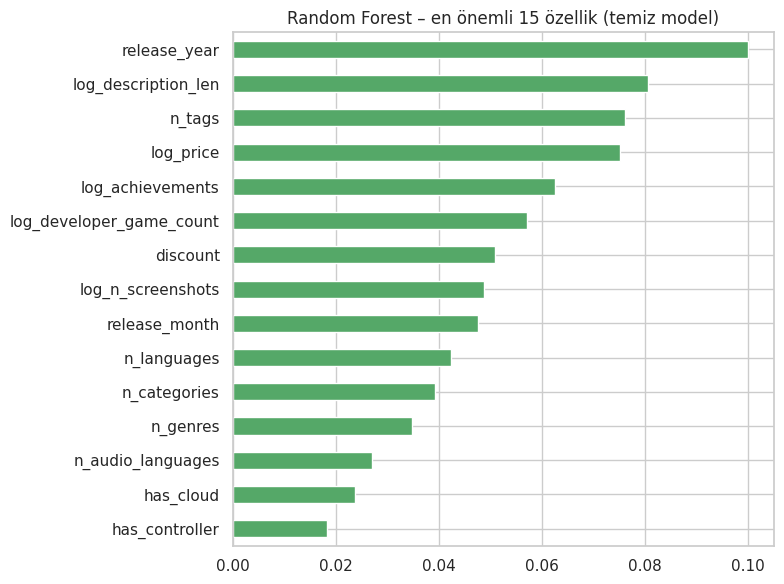

In [44]:
# En iyi temiz modelin detaylı raporu
if can_model:
    best = make_pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1,
                                                class_weight="balanced", random_state=RANDOM_STATE))
    best.fit(X.loc[idx_train], y_train)
    print(classification_report(y_test, best.predict(X.loc[idx_test]), digits=3))
    imp = pd.Series(best.named_steps["model"].feature_importances_, index=selected_features)
    imp.sort_values().tail(15).plot.barh(figsize=(8, 6), color="#55A868")
    plt.title("Random Forest – en önemli 15 özellik (temiz model)"); plt.tight_layout(); plt.show()

In [45]:
# ML'e hazır verilerin kaydedilmesi
list_cols = [c for c in clean.columns if c.endswith("_list")]
clean.drop(columns=list_cols).to_csv("steam_clean.csv", index=False)
if can_model:
    out = model_df.loc[:, selected_features + ["high_rating"]].copy()
    out["split"] = np.where(out.index.isin(idx_train), "train", "test")
    out.to_csv("steam_ml_ready.csv", index=False)
    print("Kaydedildi: steam_clean.csv, steam_ml_ready.csv  |  boyut:", out.shape)
else:
    print("Kaydedildi: steam_clean.csv")

Kaydedildi: steam_clean.csv, steam_ml_ready.csv  |  boyut: (56544, 43)


---
## Sonuç

Bu çalışmada Steam oyunları veri seti, ham hâlinden makine öğrenmesine hazır hâle getirilmiştir. Öne çıkan bulgular:

1. **Veri kalitesi:** Başlık satırındaki birleşik kolon (`DiscountDLC count`) tüm kolonları kaydırıyordu; bu hata, kod hata vermeden tamamen yanlış bir analiz üretebilirdi.
2. **Eksik veri:** Eksiklerin önemli bir kısmı pandas'ın göremediği `"[]"`, `""` ve yapısal `0` biçimindeydi. Metacritic eksikliği rastgele değildi (MAR); bu yüzden silinmedi, eksiklik göstergesi olarak modele bilgi kattı.
3. **Aykırı değerler:** Sayım ve fiyat değişkenlerindeki aykırıların çoğu hata değil, ağır kuyruklu dağılımın doğal parçasıydı; log dönüşümü ile yönetildi. Alan bilgisine aykırı değerler (ör. > 500 $) hata kabul edilip eksik olarak işaretlendi.
4. **Tutarsızlık / gürültü:** Geliştirici adlarının farklı yazımları kanonik hâle getirildi, playtest/demo kayıtları çıkarıldı, süreler dakikadan saate çevrildi.
5. **Özellik mühendisliği:** Tarih, dil, tür, kategori ve metin kolonlarından 40'a yakın yeni özellik üretildi; varyans, korelasyon ve karşılıklı bilgi ile seçim yapıldı.
6. **Veri sızıntısı:** Hedefle aynı kaynaktan gelen yayın-sonrası değişkenlerin modele girmesi skorları yapay olarak şişirmektedir. Ön işleme adımları `Pipeline` içinde yalnızca eğitim verisine fit edilerek ikinci tür sızıntı da önlenmiştir.

**Kısıtlar:** Sahip sayısı ve oynanma süreleri SteamSpy tahminidir; veri tek bir zaman kesitidir. Zamana bağlı dağılım kayması nedeniyle gerçek bir üretim senaryosunda, yayın tarihine göre **zamansal bölme** (eski oyunlarla eğit, yeni oyunlarla test et) daha gerçekçi bir değerlendirme olacaktır.